# Score new respondents and update the calibration

Score the same respondents with fixed and uncertain item parameters.
Then update the calibration across five batches using the default joint
approximation and compare parameter recovery with a single fit to all respondents.

```{note}
Posterior-approximation scoring and recursive calibration are **experimental**.
Install PyFCIRT with the `posterior` extra to run the updates.
```

## Model triplet rankings and update the calibration

In the [MGPPM example](mgppm_workflow.ipynb), respondent $p$ gives statement
$j$ utility $u_{pj}=q_j a_j\theta_{p,t(j)}-b_j$. Here $a_j>0$ is the
discrimination, $q_j$ is the keying sign, $\theta_{p,t(j)}$ is the person's
score on the trait measured by $j$, and $b_j$ is the intercept. A complete
order $r$ in a triplet gets scores $s_{rj}=2,1,0$ from first to last. Its
probability is

$$
P(Y_{pb}=r)=
\frac{\exp\!\left(\sum_{j\in b}s_{rj}u_{pj}\right)}
     {\sum_{r'\in\mathcal R_b}\exp\!\left(\sum_{j\in b}s_{r'j}u_{pj}\right)},
$$

where $Y_{pb}$ is respondent $p$'s answer to block $b$ and $\mathcal R_b$
contains its six possible orders. For $A>B>C$, the numerator is
$\exp(2u_{pA}+u_{pB})$.

Let $\boldsymbol\phi=(\mathbf a,\mathbf b,\mathbf R)$ collect the free shared
calibration parameters: loadings $\mathbf a$, statement intercepts
$\mathbf b$, and the population trait correlation matrix $\mathbf R$.
For batch $t$, let $\mathbf y_t$ denote the new rankings and
$\boldsymbol\theta_t$ the new respondents' trait scores. The posterior for the batch is

$$
p(\boldsymbol\theta_t,\boldsymbol\phi\mid\mathbf y_t)
\propto p(\mathbf y_t\mid\boldsymbol\theta_t,\boldsymbol\phi)\,
p(\boldsymbol\theta_t\mid\mathbf R)\,
q_{t-1}(\boldsymbol\phi).
$$

The first factor is the likelihood of the new rankings. The second
gives the new trait scores a population distribution with correlation
matrix $\mathbf R$. The last factor carries the previous batch's
calibration forward. The default joint approximation models the free shared parameters
together on their unconstrained scales, preserving dependence across parameter
kinds. The default `"auto"` method uses held-out draws to choose a
multivariate normal or a Gaussian mixture.
The population trait means and SDs stay fixed at zero and one, and
one intercept per triplet stays fixed at zero to set the scale.

## Simulate a questionnaire and split the respondents

Simulate 300 respondents from MGPPM's default priors. Everyone ranks the
same 24 triplets. The four-trait design keys every statement positively,
so a higher trait score increases the utility of statements that measure it.

In [1]:
import numpy as np

import pyfcirt as fc

simulated = fc.simulate("MGPPM", n_persons=300, n_traits=4, n_blocks=24, random_seed=42)
truth = simulated.idata["parameters/generation"].to_dataset()
simulated.data_coverage()

,n_blocks,size,n_persons,n_answered,n_missing
model_response_format,,,,,
MGPPM / rank,24,3,300,7200,0


In [2]:
sources = simulated.idata.design
members = sources.fc_statement.to_series().rename("statement_index").reset_index()
positions = members.statement_index.to_numpy()
design = (
    members[["block", "position"]]
    .rename(columns={"block": "block_id"})
    .assign(
        position=members.position + 1,
        statement_id=sources.statement_label.values[positions],
        trait=sources.trait.values[sources.statement_trait.values[positions]],
        keying=sources.statement_keying.values[positions],
    )
)
position = design.set_index("statement_id").position.to_dict()

# Convert each displayed statement order into its positions within the triplet.
observed = simulated.response_data(representation="categories")
responses = observed[["person", "block"]].rename(
    columns={"person": "person_id", "block": "block_id"}
)
responses["response"] = observed.category.map(
    lambda order: tuple(position[statement] for statement in order)
)
responses.head(3)

,person_id,block_id,response
0,P3,B1,"(1, 2, 3)"
1,P22,B1,"(1, 2, 3)"
2,P73,B1,"(1, 2, 3)"


Shuffle the respondent IDs and divide them into six disjoint groups of 50. Keep all 24 rankings from each respondent in the same group.

In [3]:
people = np.random.default_rng(43).permutation(sources.person.values)


def response_batch(ids):
    rows = responses.loc[responses.person_id.isin(ids)]
    return fc.ResponseTable(rows, format="block_long")


initial, *batches = [response_batch(ids) for ids in np.split(people, 6)]
calibration = fc.Model()
calibration.add_fc(
    design,
    initial.frame,
    format="block_long",
    model="MGPPM",
    response_format="rank",
)
calibration.prepare();

## Calibrate on the first 50 respondents

Retain the native draws of shared parameters so that the first scoring
batch can use the calibration posterior.

In [4]:
calibration.fit(retain_calibration=True, chains=4, draws=1000, tune=1400, random_seed=44);

## Update the calibration with each new batch

By default, [posterior approximation](../reference/generated/pyfcirt.Model.posterior_approximation.md)
represents the loadings, free intercepts and trait correlations with one joint
density and selects its family with `"auto"`. After scoring each batch, fit the
next approximation to the updated posterior.

In [5]:
from time import perf_counter

fits, timings = [calibration], []
for step, batch in enumerate(batches, start=1):
    start = perf_counter()
    prior = fits[-1].posterior_approximation(random_seed=100 + step)
    prior_seconds = perf_counter() - start

    start = perf_counter()
    scored = fits[-1].score(
        batch,
        calibration="posterior",
        approximation=prior,
        chains=4,
        draws=1000,
        tune=1400,
        random_seed=44 + step,
    )
    scoring_seconds = perf_counter() - start
    selected = prior.diagnostics["kinds"]["joint"]
    timings.append(
        {
            "Round": step,
            "Family": selected["family"],
            "Components": selected["components"],
            "Prior (s)": prior_seconds,
            "Scoring (s)": scoring_seconds,
        }
    )
    fits.append(scored)

## Fit all 300 respondents jointly

The simulated model is ready to fit with its original data, design and
default priors. Fit all rankings in one analysis for a joint benchmark.

In [6]:
simulated.fit(chains=4, draws=1000, tune=1400, random_seed=50);

## Compare fixed and posterior scoring

Use the first new batch for both scoring methods. Both start from the
50-person calibration. Fixed scoring holds the shared parameters at their
calibration means. Posterior scoring uses the first update, which
carries calibration uncertainty forward and updates the shared parameters.

For each trait, compute Pearson correlations across the same 50 people.
Compare each method's posterior mean scores and posterior SDs with the
corresponding values from the joint fit. The joint fit uses responses from
200 additional people beyond the calibration and first scoring batch.

In [7]:
fixed = calibration.score(
    batches[0],
    calibration="point",
    chains=4,
    draws=1000,
    tune=1400,
    random_seed=45,
)

In [8]:
import xarray as xr

fixed_theta = fixed.idata.posterior.theta
posterior_theta = fits[1].idata.posterior.theta.sel(person=fixed_theta.person)
joint_theta = simulated.idata.posterior.theta.sel(person=fixed_theta.person)
sample_axes = ("chain", "draw")
joint_mean = joint_theta.mean(sample_axes)
joint_sd = joint_theta.std(sample_axes, ddof=1)

correlations = {}
for label, draws in [
    ("Fixed", fixed_theta),
    ("Posterior", posterior_theta),
]:
    mean = draws.mean(sample_axes)
    sd = draws.std(sample_axes, ddof=1)
    correlations[f"{label} mean (r)"] = xr.corr(mean, joint_mean, dim="person")
    correlations[f"{label} SD (r)"] = xr.corr(sd, joint_sd, dim="person")

scoring_comparison = xr.Dataset(correlations).to_dataframe()
scoring_comparison.index = scoring_comparison.index.str.removeprefix("T").rename("Trait")
scoring_comparison.round(3)

,Fixed mean (r),Fixed SD (r),Posterior mean (r),Posterior SD (r)
Trait,,,,
1,0.985,0.899,0.995,0.917
2,0.982,0.761,0.993,0.757
3,0.987,0.963,0.995,0.952
4,0.989,0.865,0.994,0.964


## Compare parameter recovery

Compare posterior means with the generating values across the 72
loading magnitudes and 48 free intercepts. Positive keying makes each
loading equal to its magnitude. Exclude the 24 fixed reference intercepts.

Pearson's $r$ measures agreement across statements. Mean absolute
deviation (MAD) measures the average absolute error on the parameter's
scale. The final update and the joint fit use rankings from the same 300 people.

In [9]:
import pandas as pd

fixed_intercepts = simulated.idata["parameter_data/statement_intercept"].fixed_value
free = fixed_intercepts.isel(
    statement_intercept_id=fixed_intercepts.isnull()
).statement_intercept_id


def recovery(fit):
    posterior = fit.idata.posterior.to_dataset()[["loading", "statement_intercept"]]
    means, generating = xr.align(posterior.mean(sample_axes), truth, join="exact")
    values = {}
    pairs = {
        "Loading": (means.loading, generating.loading),
        "Intercept": (
            means.statement_intercept.sel(statement_intercept_id=free),
            generating.statement_intercept.sel(statement_intercept_id=free),
        ),
    }
    for label, (mean, target) in pairs.items():
        values[f"{label} r"] = xr.corr(mean, target).item()
        values[f"{label} MAD"] = abs(mean - target).mean().item()
    return values


initial = recovery(calibration)
joint_fit = recovery(simulated)
updates = pd.DataFrame(
    [
        {"Method": "Joint auto", "People": 50 * (step + 1), **recovery(fit)}
        for step, fit in enumerate(fits[1:], start=1)
    ]
)
recovery_table = pd.concat(
    [
        pd.DataFrame([{"Method": "Initial calibration", "People": 50, **initial}]),
        updates,
        pd.DataFrame([{"Method": "Joint fit", "People": 300, **joint_fit}]),
    ],
    ignore_index=True,
)
recovery_table.set_index(["Method", "People"]).round(4)

Loading r  Loading MAD  Intercept r  Intercept MAD
Method              People                                                    
Initial calibration 50         0.7674       0.2940       0.9646         0.4504
Joint auto          100        0.8278       0.2295       0.9756         0.3666
                    150        0.8790       0.2005       0.9840         0.2941
                    200        0.9039       0.1867       0.9880         0.2734
                    250        0.9006       0.1912       0.9910         0.2305
                    300        0.9004       0.1893       0.9927         0.1861
Joint fit           300        0.9082       0.1826       0.9934         0.1794

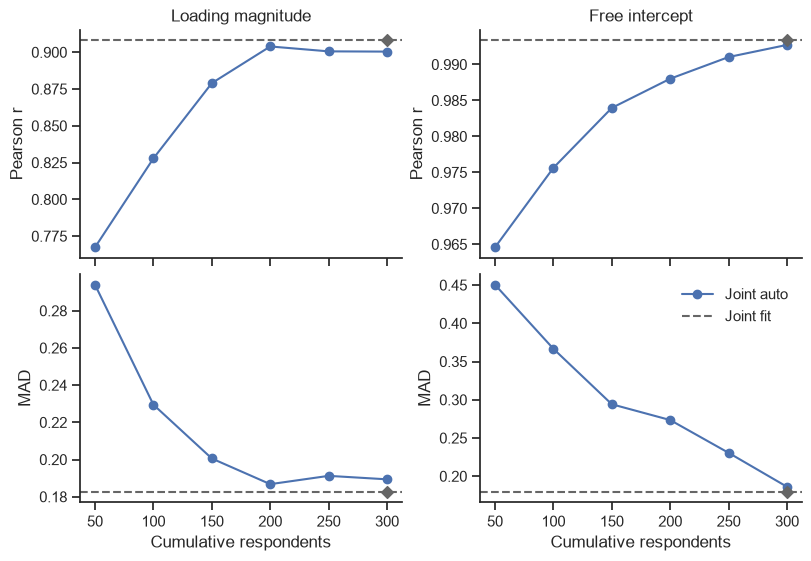

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="ticks")
metrics = ["Loading r", "Intercept r", "Loading MAD", "Intercept MAD"]
fig, axes = plt.subplots(2, 2, figsize=(8, 5.5), sharex=True, layout="constrained")
for metric, ax in zip(metrics, axes.flat, strict=True):
    ax.plot(
        [50, *updates.People],
        [initial[metric], *updates[metric]],
        marker="o",
        label="Joint auto",
    )
    ax.axhline(joint_fit[metric], color="0.4", linestyle="--", label="Joint fit")
    ax.scatter(300, joint_fit[metric], color="0.4", marker="D", zorder=3)
    ax.set(ylabel="Pearson r" if metric.endswith(" r") else "MAD")
axes[0, 0].set(title="Loading magnitude")
axes[0, 1].set(title="Free intercept")
for ax in axes[-1]:
    ax.set(xticks=range(50, 301, 50), xlabel="Cumulative respondents")
axes[1, 1].legend(frameon=False)
sns.despine()
plt.show()

At 300 respondents, the recursive updates and the joint fit give similar
recovery of the generating parameters.

- **Joint auto** gives $r=0.9004$, MAD $=0.1893$ for loadings and $r=0.9927$, MAD $=0.1861$ for free intercepts.
- **Joint fit** gives $r=0.9082$, MAD $=0.1826$ for loadings and $r=0.9934$, MAD $=0.1794$ for free intercepts.

## Check the selected priors and each scoring fit

The selected family and component count describe the joint prior in each
round. In this run, all five rounds selected a multivariate normal. Scoring time includes
graph construction, compilation, warmup and sampling. The displayed timings
come from one sequential CPU run.

In [11]:
runs = pd.DataFrame(timings).set_index("Round")
runs[["Family", "Components"]]

,Family,Components
Round,,
1,mvn,1
2,mvn,1
3,mvn,1
4,mvn,1
5,mvn,1


In [12]:
import arviz as az

diagnostics = []
for step, fit in enumerate(fits[1:], start=1):
    posterior = fit.idata.posterior.to_dataset().reset_coords(drop=True)
    with np.errstate(invalid="ignore", divide="ignore"):
        rhat = az.rhat(posterior).max().to_array().max().item()
        ess = az.ess(posterior, method="bulk").min().to_array().min().item()
    diagnostics.append(
        {
            "Round": step,
            "Max R-hat": rhat,
            "Min bulk ESS": ess,
            "Divergences": int(fit.idata.sample_stats.diverging.sum()),
        }
    )
diagnostics = pd.DataFrame(diagnostics).set_index("Round")
diagnostics.join(runs[["Prior (s)", "Scoring (s)"]]).round(3)

,Max R-hat,Min bulk ESS,Divergences,Prior (s),Scoring (s)
Round,,,,,
1,1.011,258.244,0,1.033,12.162
2,1.009,577.313,0,0.559,10.159
3,1.005,738.728,0,0.575,10.116
4,1.006,734.799,0,0.643,9.850
5,1.007,761.257,0,0.525,9.888


The initial calibration had 15 divergences. Across the five updates, the
maximum R-hat was 1.011 and there were no divergences. The joint fit also
had no divergences.